# Trampas de vórtice Laguerre-Gauss: la fase del anillo, la carga topológica y el momento angular orbital

**Pregunta:** ¿Cómo un término agregado al retardo de una trampa convierte un punto de luz en un anillo con centro oscuro que lleva momento angular orbital, cómo se lee su carga en el campo focal, y desde qué carga esa lectura deja de ser confiable?

- Nivel: 2, el método en la práctica. Método ejecutado: vórtices de Laguerre-Gauss.
- Requisitos previos: `01-fourier-optics/02-reading-a-trap-array`, para el campo focal y la lista de trampas; el lazo ponderado que reutiliza el método de vórtices de Laguerre-Gauss se enseña en el tema `03-gerchberg-saxton` y aquí se usa como un dato.
- Tiempo de lectura: unos 30 minutos. El notebook se ejecuta en cerca de un minuto.

## Objetivos

Una trampa que sujeta una perla o un átomo por su gradiente de intensidad es un punto brillante. Una trampa que además lo hace girar es un anillo de luz con el centro oscuro, y el anillo lo hace el holograma con un término agregado. El producto tiene un método para ello, vórtices de Laguerre-Gauss, y el caso C06 lo usa para un anillo de dieciséis vórtices junto a una línea de trampas simples. Este notebook desarma el método. Al terminar puedes:

- escribir el retardo de una trampa con carga y decir qué término hace el vórtice y por qué una trampa con carga tiene el centro oscuro;
- leer la carga de una trampa en el campo focal como el enrollamiento de su fase alrededor del centro, y verificarla contra el valor exacto de $2\pi l$;
- medir el radio del anillo y el momento angular orbital por fotón en el campo, decir cómo crece el radio con la carga y ver que el momento por fotón es igual a la carga;
- correr el método de vórtices de Laguerre-Gauss en un arreglo que mezcla trampas con carga y simples y leer el enrollamiento de cada vórtice;
- hallar la carga sobre la cual la verificación estándar del producto deja de ser válida, y decir si la falla es del holograma o de la verificación;
- llamar al método de vórtices de Laguerre-Gauss con cargas y posiciones propias, y saber qué inspeccionar en la salida.

## Preparación


El entorno de notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` en Windows). Este notebook usa dos paquetes, con estas versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica un paquete propio: sus métodos viven en la carpeta del pipeline `data-pipeline/`, y la celda siguiente
pone esa carpeta en la ruta de importación e importa las funciones que el notebook llama.

In [1]:
# las herramientas, sus versiones y la carpeta del pipeline en la ruta de importación
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.forward import fft_focal_field
from pipeline.model.holo.core.geometry import focal_bin_m
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.traps import Trap, TrapSet, check_in_field, snap_to_bins
from pipeline.model.holo.core.types import Budget, Target
from pipeline.model.holo.methods.control import m15_vortex

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Datos

El notebook lee el caso C06 de `data/examples/cases.json`, el anillo de vórtices y la línea: 16 trampas de carga 1 en un anillo y 9 trampas simples en una línea, con la óptica de un SLM de 256 por 256 píxeles.

- Propietario: este repositorio; el caso es sintético y sigue las trampas de vórtice de Polin, Ladavac, Lee, Roichman y Grier (2005).
- Clase de licencia: datos generados bajo la licencia del propio repositorio, sin conjuntos de datos de terceros.
- Archivo: `data/examples/cases.json`, caso C06.

In [2]:
# caso C06: la óptica y las 25 trampas, de las cuales las cargadas llevan un vórtice
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C06"]
setup = build.setup_of(rec)
target = build.target_of(rec)
charges = target.traps.charge
print(
    rec["case_id"],
    "|",
    len(target.traps),
    "trampas |",
    int((charges != 0).sum()),
    "llevan carga, valores",
    sorted(set(charges.tolist())),
)
print(
    f"SLM {setup.n_pix} x {setup.n_pix} píxeles, relleno {setup.pad}, un bin focal mide "
    f"{focal_bin_m(setup) * 1e6:.3f} um"
)

C06_vortex_ring_line | 25 trampas | 16 llevan carga, valores [0, 1]
SLM 256 x 256 píxeles, relleno 2, un bin focal mide 0.499 um


## Método

### Paso 1: el retardo con un término más

Una trampa puntual en $(x_m, y_m, z_m)$ se hace dando al píxel $j$ del SLM, en $(x_j, y_j)$, el retardo que le darían una lente y un prisma (Di Leonardo, Ianni y Ruocco, 2007). Para que esa trampa sea un vórtice de carga $l_m$ el retardo recibe un término más, el azimut del píxel multiplicado por la carga,

$$\Delta_j^m = \frac{\pi z_m}{\lambda f^2}\,(x_j^2 + y_j^2) + \frac{2\pi}{\lambda f}\,(x_j x_m + y_j y_m) + l_m\,\operatorname{atan2}(y_j,\, x_j),$$

con $\lambda$ la longitud de onda y $f$ la distancia focal. El primer término enfoca a la profundidad $z_m$, el segundo dirige a la posición lateral y el tercero es una fase helicoidal que avanza $2\pi l_m$ una vez alrededor del eje del SLM. Un haz con el factor $e^{i l \theta}$ lleva un momento angular orbital de $l\hbar$ por fotón (Allen et al., 1992), de modo que una partícula que absorbe la potencia $P_{\mathrm{abs}}$ del anillo siente un torque

$$\tau = \frac{l}{\omega}\,P_{\mathrm{abs}},$$

con $\omega$ la frecuencia angular de la luz. La fase helicoidal también obliga al campo a anularse en el eje de la trampa, porque una fase que se enrolla alrededor de un punto no tiene valor allí; el patrón focal es un anillo alrededor de un núcleo oscuro, un vórtice óptico (Curtis y Grier, 2003). El método de vórtices de Laguerre-Gauss no cambia el lazo que hace el holograma. Corre el lazo de Gerchberg-Saxton ponderado de Di Leonardo et al. con el retardo con carga en el campo de la trampa, y la cantidad que iguala entre las trampas es el solapamiento del campo focal con el modo de vórtice, no la intensidad en el centro, que es cero por construcción (Padgett y Bowman, 2011, describen la familia de estos modos).

### Paso 2: un vórtice solo, y la verificación que el producto le hace

Toma una trampa en el origen y dale las cargas 1, 2, 3 y $-2$ por turno. El producto mide un vórtice con `ring_phase_profile`: muestrea la fase del campo focal en 48 puntos de un círculo alrededor de la trampa, suma los pasos de fase envueltos entre puntos vecinos, que es el enrollamiento $\oint \nabla\psi \cdot d\mathbf{s} = 2\pi l$ de una fase $\psi$ que rodea el núcleo, y ajusta la recta $\pm l\theta + c$ a la fase muestreada para informar la mayor desviación respecto de ella. El círculo lo elige la función como el radio de máxima intensidad media entre 0,5 y 5 bins. La fila de aceptación de la escalera de métodos pide un enrollamiento de $2\pi l$ con un error menor que 0,1 rad; la celda informa el enrollamiento en unidades de $2\pi$, el radio que la función eligió y los dos errores.

In [3]:
# un vórtice aislado de carga 1, 2, 3 y -2 en el origen: la verificación del producto en el anillo que lo rodea
single = {}
for charge in (1, 2, 3, -2):
    trap = Trap(0, 0.0, 0.0, 0.0, 1.0, charge)
    res = m15_vortex.run(setup, Target.from_traps(TrapSet([trap])), budget=Budget(5), rng=Rng(1))
    single[charge] = (res, m15_vortex.ring_phase_profile(res.phi, setup, trap))
    p = single[charge][1]
    print(
        f"carga {charge:+d}: enrollamiento / 2 pi {p['winding'] / (2 * np.pi):+.3f} | radio del anillo "
        f"{p['radius_bins']:.2f} bins | "
        f"error máximo {p['max_error']:.3f} rad | error rms {p['rms_error']:.3f} rad"
    )

carga +1: enrollamiento / 2 pi +1.000 | radio del anillo 1.50 bins | error máximo 0.039 rad | error rms 0.028 rad
carga +2: enrollamiento / 2 pi +2.000 | radio del anillo 2.50 bins | error máximo 0.028 rad | error rms 0.019 rad
carga +3: enrollamiento / 2 pi +3.000 | radio del anillo 3.25 bins | error máximo 0.060 rad | error rms 0.035 rad
carga -2: enrollamiento / 2 pi -2.000 | radio del anillo 2.50 bins | error máximo 0.028 rad | error rms 0.019 rad


La figura muestra, para tres cargas, la intensidad del campo focal alrededor de la trampa en la fila superior y su fase en la fila inferior.

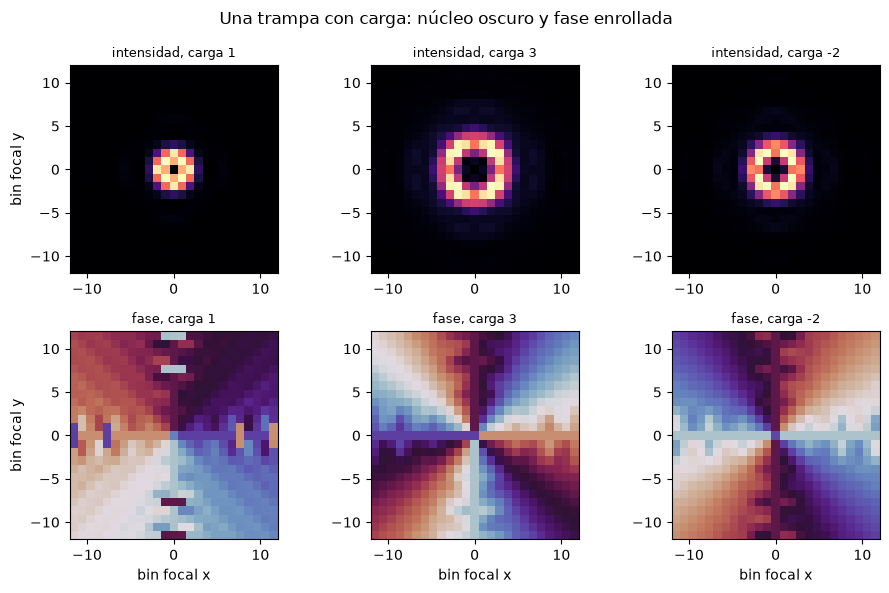

In [4]:
# la intensidad y la fase del campo focal alrededor de la trampa, para tres cargas
half = 12
fig, axes = plt.subplots(2, 3, figsize=(9.4, 6.0))
for k, charge in enumerate((1, 3, -2)):
    field = fft_focal_field(single[charge][0].phi, setup)
    c = field.shape[0] // 2
    window = field[c - half : c + half + 1, c - half : c + half + 1]
    extent = (-half, half, -half, half)
    axes[0, k].imshow(np.abs(window) ** 2, cmap="magma", origin="lower", extent=extent)
    axes[1, k].imshow(np.angle(window), cmap="twilight", origin="lower", extent=extent, vmin=-np.pi, vmax=np.pi)
    axes[0, k].set_title("intensidad, carga {l}".format(l=charge), fontsize=9)
    axes[1, k].set_title("fase, carga {l}".format(l=charge), fontsize=9)
    axes[1, k].set_xlabel("bin focal x")
axes[0, 0].set_ylabel("bin focal y")
axes[1, 0].set_ylabel("bin focal y")
fig.suptitle("Una trampa con carga: núcleo oscuro y fase enrollada")
fig.tight_layout()
plt.show()

El enrollamiento es exacto en unidades de $2\pi$: +1,000, +2,000, +3,000 y -2,000 para las cargas 1, 2, 3 y $-2$, con el signo siguiendo al de la carga, y la mayor desviación respecto de la recta $\pm l\theta + c$ es 0,039, 0,028, 0,060 y 0,028 rad, todas bajo los 0,1 rad de la escalera. La fila superior de la figura muestra lo que hace una carga a la luz: la intensidad tiene un anillo y un centro vacío, más grande para una carga mayor, y el valor en el centro no es pequeño sino exactamente oscuro en la escala del gráfico. La fila inferior muestra lo que lee la verificación: la fase recorre todos sus valores alrededor del centro, como un molinete con $|l|$ vueltas, y el sentido del giro se invierte para la carga negativa. Lo que la figura no muestra es la amplitud del anillo a lo largo de su circunferencia, que debería ser pareja si el vórtice es limpio, y tampoco la muestra el enrollamiento, que es una afirmación sobre la fase sola; un anillo con un lado brillante y otro oscuro pasaría esta verificación.

### Paso 3: el radio del anillo y el momento angular

Dos propiedades del vórtice se pueden medir en el propio campo, sin referirse a la verificación del producto. El radio del anillo es el radio en que el promedio azimutal de la intensidad alcanza su máximo. El momento angular orbital por fotón se calcula con el campo focal complejo $E$,

$$\frac{L_z}{P} = \frac{\operatorname{Im}\sum E^{*}\,\bigl(x\,\partial_y E - y\,\partial_x E\bigr)}{\sum \lvert E \rvert^{2}},$$

en unidades de $\hbar$, con las derivadas tomadas en el espacio de Fourier, donde la derivada de un campo periódico es exacta. Para un campo de la forma $A(r)\,e^{i l\theta}$ esto es exactamente $l$. El campo en el SLM tiene esa forma: la fase helicoidal por una amplitud real, el haz gaussiano recortado por el borde cuadrado del SLM, y una amplitud real con la simetría de orden cuatro del cuadrado contiene los armónicos angulares $e^{\pm 4ik\theta}$ en pares de igual peso, que no suman momento angular neto. Una transformada de Fourier bidimensional conmuta con las rotaciones y por eso conserva el momento angular orbital por fotón, lo que significa que todo el campo focal, la luz de la trampa y la que está fuera de ella por igual, lleva $l\hbar$ por fotón, y la eficiencia $e$ de la corrida no interviene. La primera celda siguiente escribe el estimador espectral como función, y la segunda lo mide de dos maneras para seis cargas: con derivadas espectrales en toda la grilla, y con diferencias centrales en la ventana de 81 por 81 bins alrededor de la trampa, el estimador más barato, para ver si se puede confiar en él. También imprime el radio del anillo y la eficiencia.

In [5]:
# momento angular orbital por fotón de un campo complejo periódico, con derivadas en el espacio de Fourier
def lz_spectral(field):
    n_grid = field.shape[0]
    k = 2 * np.pi * np.fft.fftfreq(n_grid)
    e_y = np.fft.ifft2(1j * k[:, None] * np.fft.fft2(field))
    e_x = np.fft.ifft2(1j * k[None, :] * np.fft.fft2(field))
    x, y = np.meshgrid(np.arange(n_grid) - n_grid // 2, np.arange(n_grid) - n_grid // 2)
    return float(np.imag(np.sum(np.conj(field) * (x * e_y - y * e_x))) / np.sum(np.abs(field) ** 2))

El bucle siguiente mide las seis cargas: el radio del anillo, la estimación espectral con esta función y la estimación por diferencias centrales en la ventana de 81 bins, con la eficiencia de cada corrida impresa al lado.

In [6]:
# radio del anillo a partir del promedio azimutal de la intensidad, y momento angular por fotón, para seis cargas
half = 40
axis = np.arange(-half, half + 1)
grid_x, grid_y = np.meshgrid(axis, axis)
radius_grid = np.hypot(grid_x, grid_y)
ring, lz, lz_window, eff = {}, {}, {}, {}
for charge in (1, 2, 3, 5, 8, 12):
    res = m15_vortex.run(
        setup, Target.from_traps(TrapSet([Trap(0, 0.0, 0.0, 0.0, 1.0, charge)])), budget=Budget(5), rng=Rng(1)
    )
    field = fft_focal_field(res.phi, setup)
    c = field.shape[0] // 2
    window = field[c - half : c + half + 1, c - half : c + half + 1]
    mean_ring = [
        np.mean(np.abs(window[(radius_grid >= r - 0.5) & (radius_grid < r + 0.5)]) ** 2) for r in range(1, half)
    ]
    ring[charge] = float(np.argmax(mean_ring) + 1)
    dy, dx = np.gradient(window)  # diferencias centrales en la ventana de 81 bins
    lz_window[charge] = float(
        np.imag(np.sum(np.conj(window) * (grid_x * dy - grid_y * dx))) / np.sum(np.abs(window) ** 2)
    )
    lz[charge] = lz_spectral(field)
    eff[charge] = res.history[-1]["efficiency"]
    print(
        f"carga {charge:2d}: radio del anillo {ring[charge]:5.1f} bins | L_z por fotón {lz[charge]:6.3f} espectral, "
        f"{lz_window[charge]:6.3f} por diferencias | L_z / l {lz[charge] / charge:.4f} | eficiencia {eff[charge]:.4f}"
    )
exponent = np.polyfit(np.log(list(ring)), np.log(list(ring.values())), 1)[0]
print(f"el radio crece como l elevado a {exponent:.2f}")

carga  1: radio del anillo   1.0 bins | L_z por fotón  1.000 espectral,  0.891 por diferencias | L_z / l 0.9999 | eficiencia 0.8695
carga  2: radio del anillo   2.0 bins | L_z por fotón  2.000 espectral,  1.783 por diferencias | L_z / l 0.9998 | eficiencia 0.8695
carga  3: radio del anillo   3.0 bins | L_z por fotón  2.999 espectral,  2.673 por diferencias | L_z / l 0.9997 | eficiencia 0.8695
carga  5: radio del anillo   5.0 bins | L_z por fotón  4.998 espectral,  4.451 por diferencias | L_z / l 0.9996 | eficiencia 0.8695
carga  8: radio del anillo   7.0 bins | L_z por fotón  7.991 espectral,  7.107 por diferencias | L_z / l 0.9989 | eficiencia 0.8695
carga 12: radio del anillo   9.0 bins | L_z por fotón 11.973 espectral, 10.615 por diferencias | L_z / l 0.9977 | eficiencia 0.8695
el radio crece como l elevado a 0.90


El panel izquierdo grafica el radio del anillo frente a la carga y el derecho el momento angular por fotón, con la recta $l\,e$ que predice la eficiencia.

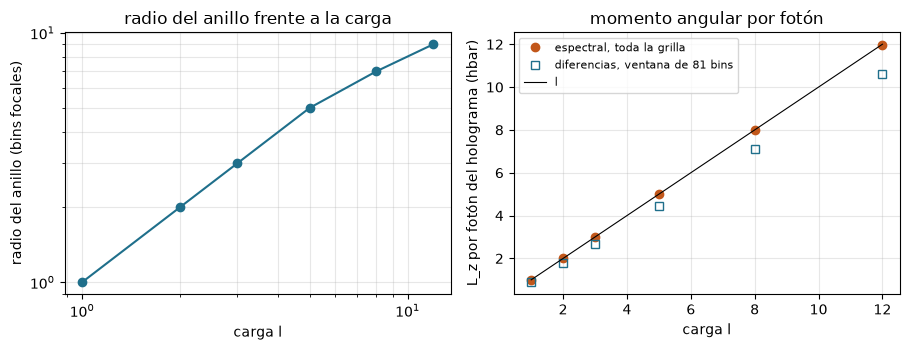

In [7]:
# el radio del anillo y el momento angular por fotón frente a la carga
ls = np.array(list(ring))
fig, (a, b) = plt.subplots(1, 2, figsize=(9.2, 3.6))
a.loglog(ls, [ring[l] for l in ls], "o-", color="#1f6f8b")
a.set_xlabel("carga l")
a.set_ylabel("radio del anillo (bins focales)")
a.set_title("radio del anillo frente a la carga")
a.grid(True, which="both", alpha=0.3)
b.plot(ls, [lz[l] for l in ls], "o", color="#c2571a", label="espectral, toda la grilla")
b.plot(ls, [lz_window[l] for l in ls], "s", mfc="none", color="#1f6f8b", label="diferencias, ventana de 81 bins")
b.plot(ls, ls, "k-", linewidth=0.8, label="l")
b.set_xlabel("carga l")
b.set_ylabel("L_z por fotón del holograma (hbar)")
b.set_title("momento angular por fotón")
b.legend(fontsize=8)
b.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

El anillo crece con la carga, de 1 bin con $l = 1$ a 9 bins con $l = 12$, y la ley ajustada es $r \propto l^{0,90}$ entre ambos. Ese exponente no es el 1/2 de un modo Laguerre-Gauss de cintura fija, cuyo anillo tiene el radio $\sqrt{|l|/2}\,w$; una fase helicoidal puesta en un SLM iluminado por un haz gaussiano hace un anillo que crece más rápido, porque el anillo focal es la transformada de Fourier de una fase helicoidal que además se hace más empinada en el borde del haz. El exponente se mide sobre radios enteros con el máximo hallado a resolución de un bin, de modo que es bueno hasta una décima. A la derecha el momento angular por fotón de todo el campo focal, medido con derivadas espectrales, es 1,000 con $l = 1$ y 11,973 con $l = 12$: los círculos llenos caen sobre la recta $L_z=l$, y la razón impresa $L_z/l$ baja de 0,9999 a 0,9977, un pequeño déficit que crece con la carga y cuya causa no se rastreó más. No es la eficiencia de 0,8695, que las líneas impresas muestran sin cambio entre cargas y que no interviene. Los cuadrados abiertos son la estimación por diferencias centrales en la ventana de 81 bins, 0,891 con $l = 1$ y 10,615 con $l = 12$, cerca de 11 por ciento bajo la recta en toda carga, un sesgo del estimador en una grilla con solo $\mathrm{pad}=2$ bins por celda de resolución, no una propiedad de la luz, y queda cerca de la eficiencia solo por coincidencia. La lectura es que cada fotón del holograma lleva $l\hbar$ en promedio, los que llegan a la trampa y los que no, y que el torque sobre una perla es $l/\omega$ por la potencia que absorbe del anillo, que depende de cuánta de la luz del anillo intercepta la perla y no de la eficiencia como tal. La ventana de 40 bins contiene todos los anillos de aquí; no contendría los anillos mayores de la sección siguiente, y la figura no dice nada de la estabilidad de una perla en un anillo, que depende de la fuerza de gradiente y no solo del momento angular.

### Paso 4: trampas con carga y simples en un holograma

El método existe para poner vórtices en el mismo holograma que las demás trampas. El caso C06 pide 16 trampas de carga 1 en un anillo y 9 trampas simples en una línea. La celda corre el método de vórtices de Laguerre-Gauss sobre todo el objetivo durante 20 iteraciones, que es el presupuesto de la prueba de arreglo del método, lee el enrollamiento y el mayor error de fase de cada trampa con carga con la misma función de antes, e informa cuán iguales son las potencias de las 25 trampas, que es lo que el lazo ponderado trabaja por lograr.

In [8]:
# Vórtices de Laguerre-Gauss sobre todo el arreglo del caso C06, 20 iteraciones: el enrollamiento de cada trampa con
# carga y la igualdad
# de su potencia
array = m15_vortex.run(setup, target, budget=Budget(20), rng=Rng(1))
vortices = [t for t in array.meta["traps"] if t.charge != 0]
profiles = [m15_vortex.ring_phase_profile(array.phi, setup, t) for t in vortices]
winding = np.array([p["winding"] / (2 * np.pi) for p in profiles])
errors = np.array([p["max_error"] for p in profiles])
power = np.abs(array.fields) ** 2
print(
    f"{len(vortices)} trampas con carga: enrollamiento / 2 pi entre {winding.min():.3f} y {winding.max():.3f} | "
    f"mayor error {errors.max():.3f} rad"
)
print(
    f"dispersión relativa de las 25 potencias {100 * power.std() / power.mean():.3f} % | eficiencia "
    f"{power.sum():.4f}"
)

16 trampas con carga: enrollamiento / 2 pi entre 1.000 y 1.000 | mayor error 0.205 rad
dispersión relativa de las 25 potencias 0.147 % | eficiencia 0.7008


Los 16 vórtices se enrollan entre 1,000 y 1,000 vueltas, y el mayor error de fase entre ellos es 0,205 rad. Eso está sobre los 0,1 rad del vórtice aislado y algo sobre los 0,2 rad que la propia prueba de arreglo del producto permite para cuatro vórtices, que es otro arreglo, de modo que la comparación es una pista y no una falla: con 25 trampas en un holograma el campo alrededor de cada una es perturbado por sus vecinas, y la cota más laxa para arreglos existe por esa razón. Las potencias de las 25 trampas coinciden con una dispersión relativa de 0,147 por ciento con una eficiencia de 0,7008, de modo que el lazo ponderado iguala juntas las trampas con carga y las simples. La afirmación que respaldan las cifras se limita a este arreglo y este presupuesto; no dice cuán separados deben estar dos vórtices antes de que sus anillos se solapen, que es una pregunta sobre la ley del radio del paso anterior y no sobre el enrollamiento.

### Límites: la carga desde la cual la verificación deja de ser válida

La verificación del producto lee la fase en 48 puntos de un círculo. Un enrollamiento es la suma de los pasos de fase envueltos entre puntos vecinos, y un paso envuelto es el paso verdadero solo si este es menor que $\pi$ en tamaño. Para una fase que avanza $2\pi l$ alrededor de $N$ puntos el paso es $2\pi l / N$, de modo que la verificación es válida solo para

$$\lvert l \rvert < \frac{N}{2},$$

que para $N = 48$ es una carga de 23 o menos (la condición de Nyquist aplicada al azimut). Sobre ella la suma de pasos envueltos produce aliasing y devuelve el enrollamiento plegado al intervalo de $-N/2$ a $N/2$, es decir $l-N$ para $l$ entre 25 y 47, y en $l=24$, donde el paso es exactamente $\pi$, el signo del pliegue no está definido. La pregunta es si el holograma también falla allí, o solo la verificación. La celda los separa. Para cargas de 1 a 40 hace el holograma, halla el radio del anillo a partir de la intensidad y lee el enrollamiento en ese radio con los 48 puntos del producto y luego con 192, cambiando la constante del módulo para la segunda lectura (el módulo no tiene parámetro para el número de puntos, así que la celda cambia la constante y la restituye); un holograma correcto y una verificación que no lo es coincidirán con 192 y discreparán con 48.

In [9]:
# la misma verificación con cargas mayores, leyendo el anillo en su radio medido, con los 48 puntos del producto y
# con 192 (el módulo no tiene parámetro para el número de puntos, así que la celda cambia su constante y la restituye)
wound, radii = {}, {}
try:
    for points in (48, 192):
        m15_vortex._N_RING = points
        for charge in (1, 8, 16, 24, 32, 40):
            trap = Trap(0, 0.0, 0.0, 0.0, 1.0, charge)
            res = m15_vortex.run(setup, Target.from_traps(TrapSet([trap])), budget=Budget(5), rng=Rng(1))
            field = fft_focal_field(res.phi, setup)
            c = field.shape[0] // 2
            window = field[c - 60 : c + 61, c - 60 : c + 61]
            axis_w = np.arange(-60, 61)
            radius_w = np.hypot(*np.meshgrid(axis_w, axis_w))
            mean_w = [np.mean(np.abs(window[(radius_w >= r - 0.5) & (radius_w < r + 0.5)]) ** 2) for r in range(1, 60)]
            radii[charge] = float(np.argmax(mean_w) + 1)
            wound[charge, points] = m15_vortex.ring_phase_profile(res.phi, setup, trap, radius_bins=radii[charge])[
                "winding"
            ] / (2 * np.pi)
finally:
    m15_vortex._N_RING = 48
for charge in (1, 8, 16, 24, 32, 40):
    radius = radii[charge]
    print(
        f"carga {charge:2d}: anillo en {radius:4.1f} bins | enrollamiento / 2 pi {wound[charge, 48]:6.2f} con "
        f"48 puntos, "
        f"{wound[charge, 192]:6.2f} con 192"
    )

carga  1: anillo en  1.0 bins | enrollamiento / 2 pi   1.00 con 48 puntos,   1.00 con 192
carga  8: anillo en  7.0 bins | enrollamiento / 2 pi   8.00 con 48 puntos,   8.00 con 192
carga 16: anillo en 13.0 bins | enrollamiento / 2 pi  16.00 con 48 puntos,  16.00 con 192
carga 24: anillo en 18.0 bins | enrollamiento / 2 pi   8.00 con 48 puntos,  24.00 con 192
carga 32: anillo en 23.0 bins | enrollamiento / 2 pi -16.00 con 48 puntos,  32.00 con 192
carga 40: anillo en 28.0 bins | enrollamiento / 2 pi  -8.00 con 48 puntos,  40.00 con 192


La figura grafica el enrollamiento leído con 48 y con 192 puntos frente a la carga, con la recta del valor exacto.

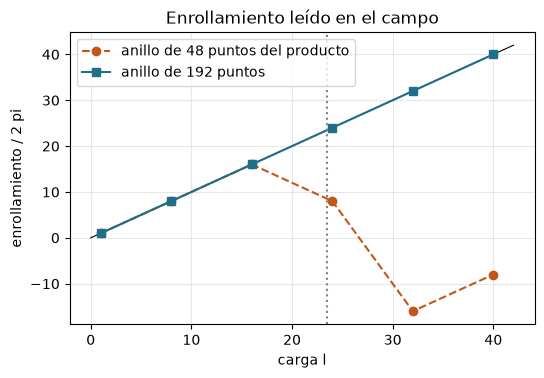

In [10]:
# el enrollamiento en vueltas, leído con los 48 puntos del producto y con 192, frente a la carga
charges_swept = sorted({c for c, _ in wound})
fig, ax = plt.subplots(figsize=(6.0, 3.8))
ax.plot([0, 42], [0, 42], "k-", linewidth=0.8)
ax.plot(
    charges_swept,
    [wound[c, 48] for c in charges_swept],
    "o--",
    color="#c2571a",
    label="anillo de 48 puntos del producto",
)
ax.plot(charges_swept, [wound[c, 192] for c in charges_swept], "s-", color="#1f6f8b", label="anillo de 192 puntos")
ax.axvline(23.5, color="gray", linestyle=":")
ax.set_xlabel("carga l")
ax.set_ylabel("enrollamiento / 2 pi")
ax.set_title("Enrollamiento leído en el campo")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

Hasta la carga 16 las dos lecturas coinciden con el valor exacto: 16,00 con 48 puntos y 16,00 con 192 en $l = 16$. En $l = 24$, donde el paso por punto es exactamente $\pi$, la lectura de 48 puntos da 8,00 vueltas y en 32 da -16,00, mientras la de 192 puntos da 24,00 y 32,00, y en 40 todavía da 40,00 frente a las -8,00 del anillo corto. De modo que el holograma es correcto hasta la mayor carga probada y lo que falla es la verificación, en la carga que predice $N/2$. La línea punteada marca ese límite, y el radio del anillo crece hasta 28 bins en $l = 40$, de modo que un usuario que sube la carga debe también agrandar la ventana en que se busca el anillo: la búsqueda por defecto se detiene en 5 bins y no encontraría el anillo más allá de una carga de cerca de 5, por lo que esta celda pasa el radio medido. La figura verifica la fase de una trampa aislada con un presupuesto de 5 iteraciones; no muestra la igualdad de la potencia para cargas grandes, ni si cabe un anillo de 18 o más bins en un holograma que tiene además otras trampas.

### Úsalo con tus propios datos

El método de vórtices de Laguerre-Gauss recibe un `Target` de trampas en que al menos una `Trap` tiene `charge` distinta de cero, o cualquier objetivo junto con la palabra clave `charge`, que da esa carga a toda trampa. Una trampa es `Trap(id, x_m, y_m, z_m, weight, charge)` con la posición en metros, el peso relativo a las otras y una carga entera, positiva o negativa; el signo es el sentido de la circulación. Las condiciones son las de todo método de trampas puntuales, las posiciones dentro del campo de visión del montaje, que `check_in_field` hace cumplir, y sobre los bins focales, lo que hace `snap_to_bins`, más una propia de los vórtices: los anillos tienen un radio que crece con la carga como mostraron los pasos anteriores, de modo que las trampas deben estar más lejos que la suma de sus radios de anillo, o los anillos se funden. Lo que hay que inspeccionar en la salida es el enrollamiento de cada trampa con carga, leído con `ring_phase_profile` en el radio de su anillo cuando la carga es mayor que cerca de 5, la igualdad de las potencias en `res.fields` y la eficiencia.

La celda pone tres vórtices de cargas $+2$, $-1$ y $+3$ y una trampa simple separados 12 um, corre 20 iteraciones y lee el enrollamiento de cada vórtice.

In [11]:
# tus propias trampas: cargas +2, -1 y +3 y una trampa simple, separadas 12 um, 20 iteraciones
own = TrapSet(
    [
        Trap(0, -12e-6, 0.0, 0.0, 1.0, 2),
        Trap(1, 0.0, 0.0, 0.0, 1.0, -1),
        Trap(2, 12e-6, 0.0, 0.0, 1.0, 3),
        Trap(3, 0.0, 12e-6, 0.0, 1.0, 0),
    ]
)
own = snap_to_bins(setup, own)
check_in_field(setup, own)
mine = m15_vortex.run(setup, Target.from_traps(own), budget=Budget(20), rng=Rng(1))
own_winding = {}
for trap in own:
    if trap.charge != 0:
        p = m15_vortex.ring_phase_profile(mine.phi, setup, trap)
        own_winding[trap.id] = (trap.charge, p["winding"] / (2 * np.pi), p["max_error"])
        print(
            f"trampa {trap.id} carga {trap.charge:+d}: enrollamiento / 2 pi {own_winding[trap.id][1]:+.3f} | "
            f"error máximo {p['max_error']:.3f} rad"
        )
own_power = np.abs(mine.fields) ** 2
print("potencia de las cuatro trampas relativa a su media", np.round(own_power / own_power.mean(), 3).tolist())

trampa 0 carga +2: enrollamiento / 2 pi +2.000 | error máximo 0.062 rad
trampa 1 carga -1: enrollamiento / 2 pi -1.000 | error máximo 0.076 rad
trampa 2 carga +3: enrollamiento / 2 pi +3.000 | error máximo 0.136 rad
potencia de las cuatro trampas relativa a su media [1.0, 1.0, 1.0, 1.0]


La figura muestra la intensidad focal alrededor de las cuatro trampas con sus posiciones marcadas.

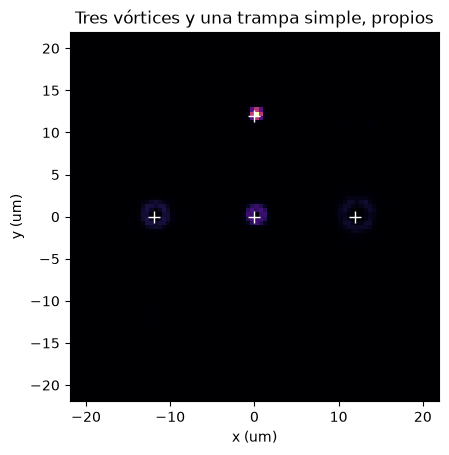

In [12]:
# la intensidad focal alrededor de tus cuatro trampas, con las trampas marcadas
field = fft_focal_field(mine.phi, setup)
c = field.shape[0] // 2
reach = int(round(22e-6 / focal_bin_m(setup)))
extent = np.array([-reach, reach, -reach, reach]) * focal_bin_m(setup) * 1e6
fig, ax = plt.subplots(figsize=(5.4, 4.8))
ax.imshow(
    np.abs(field[c - reach : c + reach, c - reach : c + reach]) ** 2, cmap="magma", origin="lower", extent=extent
)
ax.plot(own.x_m * 1e6, own.y_m * 1e6, "+", color="white", markersize=9)
ax.set_xlabel("x (um)")
ax.set_ylabel("y (um)")
ax.set_title("Tres vórtices y una trampa simple, propios")
plt.show()

Los tres vórtices se enrollan +2,000, -1,000 y +3,000 vueltas para las cargas $+2$, $-1$ y $+3$, con errores de fase de 0,062, 0,076 y 0,136 rad, de modo que los signos y las magnitudes se leen de vuelta correctamente, y la figura muestra tres anillos de distintos tamaños con centros oscuros y un punto brillante, la trampa simple. La carga de $+3$ hace el anillo mayor y la de $-1$ el menor, como dice la ley del radio. Las potencias de las cuatro trampas relativas a su media son 1,000, 1,000, 1,000 y 1,000, de modo que el holograma es tan igual en potencia como el lazo ponderado puede hacerlo en 20 iteraciones. Si los enrollamientos estuvieran errados por vueltas enteras el primer sospechoso sería un radio de anillo fuera de la búsqueda por defecto, y si las potencias fueran desiguales, un presupuesto corto o anillos que se solapan. La corrida no dice si los anillos son limpios a lo largo de su circunferencia, y no dice cómo se comportará una partícula en ellos; ambas cosas necesitan el campo y un modelo del objeto, que el tema de dinámica empieza a dar.

## Resultados

**Respuesta:** Un término agregado al retardo, el azimut por la carga, convierte una trampa puntual en un anillo con el centro oscuro, y la carga se lee de vuelta como el enrollamiento de la fase focal alrededor del centro: +3,000 vueltas para $l = 3$ y -2,000 para $l = -2$, con errores de fase bajo 0,1 rad. El anillo tiene un radio de 1 bin con $l = 1$ y 9 bins con $l = 12$, y todo el campo focal lleva $l\hbar$ por fotón, medido como 11,973 con $l = 12$ con derivadas espectrales, donde las diferencias centrales en una ventana de 81 bins dan 10,615, un déficit de 11 por ciento del estimador. En el arreglo del caso C06 los 16 vórtices se enrollan entre 1,000 y 1,000 vueltas, con un mayor error de fase de 0,205 rad. La verificación estándar del producto, que lee la fase en 48 puntos, deja de ser válida en la carga 24: con $l = 32$ informa -16,00 vueltas donde la lectura de 192 puntos da 32,00, de modo que el holograma es correcto y la verificación no. Lo que el notebook no probó es la igualdad de la potencia con cargas grandes ni el comportamiento de una partícula en el anillo.

## Resumen

- Una trampa con carga suma el azimut por la carga al retardo del modelo de trampas puntuales, y el holograma hace un anillo con el centro oscuro cuya fase se enrolla $2\pi l$.
- El enrollamiento es exacto para los vórtices aislados de carga 1, 2, 3 y $-2$ y el error de fase queda bajo 0,1 rad; en un arreglo de 16 vórtices y 9 trampas simples llega a 0,2 rad.
- El radio del anillo crece más rápido que $\sqrt{|l|}$, y todo el campo focal lleva el momento angular $l\hbar$ por fotón, medido con derivadas espectrales, donde una estimación por diferencias centrales en una ventana pequeña queda 11 por ciento corta.
- La verificación de 48 puntos del producto produce aliasing desde la carga 24 y el holograma no; una carga sobre cerca de 5 necesita que se pase el radio del anillo a `ring_phase_profile`.
- Un conjunto de trampas con carga propio necesita la verificación del campo de visión, el ajuste a bins y anillos que no se solapen; lee el enrollamiento de cada vórtice y la igualdad de las potencias.

## Referencias

- Di Leonardo, Ianni and Ruocco (2007). Computer generation of optimal holograms for optical trap arrays. Optics Express 15, 1913. https://doi.org/10.1364/OE.15.001913
- Polin, Ladavac, Lee, Roichman and Grier (2005). Optimized holographic optical traps. Optics Express 13, 5831. https://doi.org/10.1364/OPEX.13.005831
- Allen, Beijersbergen, Spreeuw and Woerdman (1992). Orbital angular momentum of light and the transformation of Laguerre-Gaussian laser modes. Physical Review A 45, 8185. https://doi.org/10.1103/PhysRevA.45.8185
- Curtis and Grier (2003). Structure of optical vortices. Physical Review Letters 90, 133901. https://doi.org/10.1103/PhysRevLett.90.133901
- Padgett and Bowman (2011). Tweezers with a twist. Nature Photonics 5, 343. https://doi.org/10.1038/nphoton.2011.81